# A first ensemble map

This tutorial makes a map from scattered measurements with Spatialize, from the data to the estimate,
its precision and the ensemble behind both. The field is the ground elevation around Walker Lake,
Nevada, measured by the U.S. Geological Survey on a 260 × 300 grid. The tutorial keeps 1 % of it as
data and the rest as the truth to check the map against.

## What you will learn

- What an ensemble of Spatialize is, namely many partitions of the domain, a local prediction in each
  cell, and the collection of predictions at every location, the *members*.
- How to estimate on a grid (`esi_griddata`) and at scattered locations (`esi_nongriddata`).
- How to read the estimate, its precision and the members behind them.

It answers one question. *How do I turn scattered data into a map, and what does the map rest on?*

## The idea

Spatialize does not fit one model to the whole domain. It draws a random partition of the domain into
cells, predicts inside each cell from the data that fall in it, and repeats with many independent
partitions. At a location, each partition gives one prediction, a *member*. Together they form the
ensemble, whose summary, by default the mean, is the estimate.

![The ESI procedure for one location with three random partitions](ESI_procedure.png)

The partition is the **encoder** and the local interpolator the **decoder**. Averaging over random
partitions removes the arbitrary boundaries of any single partition, while the spread of the members
says how much the prediction depends on how the domain is cut. In probabilistic terms, with
$S^*$ a random partition and $S^*_k$ the cell holding the location $x$,

$$p\big(Z(x)\big) = \mathbb{E}_{S^*}\Big[\, p\big(Z(x) \mid x \in S^*_k\big) \Big],$$

the law of the value at $x$ is the law within its cell, averaged over the partitions. The method is
described in Egaña et al. ([2021](https://link.springer.com/article/10.1007/s11053-021-09860-2)),
its adaptive decoder and the Bayesian reading in
[Egaña et al. (2025)](https://www.nature.com/articles/s41598-025-08844-z), and the library in
[Navarro et al. (2025)](https://arxiv.org/abs/2507.17867).

## Step by step

### The session

The session holds settings that apply to every call. A partition fine enough leaves some cells
without data, and `empty_cells="coarsen"` predicts the locations of such a cell from the nearest
coarser cell that holds data, so that every member is defined. The gallery's tutorials use it.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import spatialize
from spatialize.data import load_elevation_walker_lake
from spatialize.evaluation import MAE
from spatialize.gs.esi import esi_pareto_hparams_search, esi_griddata, esi_nongriddata
import spatialize.gs.esi.scorefunction as sf

spatialize.session.set(empty_cells="coarsen")

### The data

`load_elevation_walker_lake` returns 780 data drawn at random from the grid (1 % of it) and the whole
grid. Coordinates are in kilometres, elevations in metres.

780 data, a 260 × 300 grid, elevation from 1194 to 3414 m


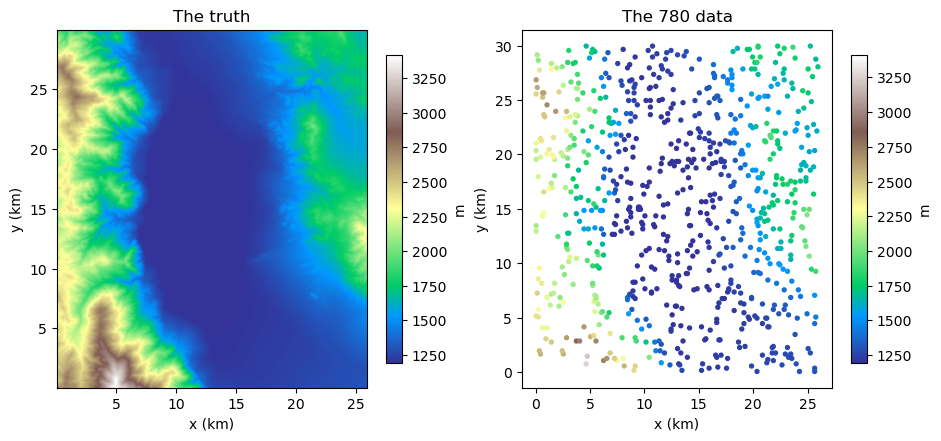

In [2]:
samples, grid = load_elevation_walker_lake()
points, values = samples[["x", "y"]].values, samples["elevation"].values
xs, ys = np.sort(grid["x"].unique()), np.sort(grid["y"].unique())
truth = grid.sort_values(["x", "y"])["elevation"].values.reshape(len(xs), len(ys))
extent = (xs[0], xs[-1], ys[0], ys[-1])
print(f"{len(points)} data, a {len(xs)} × {len(ys)} grid, elevation from {values.min():.0f} to {values.max():.0f} m")

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
im = axes[0].imshow(truth.T, origin="lower", extent=extent, cmap="terrain")
axes[0].set_title("The truth")
fig.colorbar(im, ax=axes[0], shrink=0.8, label="m")
sc = axes[1].scatter(points[:, 0], points[:, 1], c=values, s=8, cmap="terrain")
axes[1].set_title("The 780 data")
axes[1].set_aspect("equal")
fig.colorbar(sc, ax=axes[1], shrink=0.8, label="m")
for ax in axes:
    ax.set_xlabel("x (km)"); ax.set_ylabel("y (km)")
plt.show()

The lake is the flat floor in the middle, about a quarter of the area at 1 194 m. The Wassuk Range
rises steeply to the west and lower hills to the east. The ranges run north–south, so the elevation
changes faster across them than along them. A decoder with one isotropic weighting would draw round
bull's-eyes around the data, so this tutorial uses the adaptive IDW (`"adaptiveidw"`), which fits its
own exponent and anisotropy in every cell.

### Choosing the parameters

The granularity of the partitions, `alpha` in [0, 1), is chosen on the Pareto frontier between the
encoder and the decoder errors, read at its knee, as the tutorial *Choosing an ensemble with the
Pareto search* explains. A five-fold cross-validation keeps the search short.

In [3]:
search = esi_pareto_hparams_search(points, values, local_interpolator="adaptiveidw", n_partitions=[100],
                                   alpha=[0.7, 0.8, 0.9, 0.95, 0.98], k=5, scoring=sf.mae, seed=0)
best = search.best_result(strategy="knee")
search

======================================================================================
spatialize · ESI Pareto search                                  mondrian · adaptiveidw
======================================================================================
Search                                      Best (min decoder error)
  configurations                         5    alpha                               0.95
  on the frontier                        2    metric                               mae
  partition                       mondrian    n_partitions                         100
  decoder                      adaptiveidw
--------------------------------------------------------------------------------------
Frontier, by encoder error
      alpha  encoder ε̂  decoder error
  ------------------------------------
  #1   0.98       328.9          28.26
  #2   0.95        1520          27.79
--------------------------------------------------------------------------------------
best_result(strategy) · best_for_tau(tau) · frontier · all_results
======================================================================================

### The map on a grid

`esi_griddata` takes the grid as an array of shape `(2, nx, ny)`, as `numpy.meshgrid` with
`indexing="ij"` builds it, and returns results of the same shape. `best_params_found` passes the
chosen configuration, while the number of partitions is given at the call, here 200.

In [4]:
xi = np.stack(np.meshgrid(xs, ys, indexing="ij"))
print(f"grid of queries of shape {xi.shape}")
result = esi_griddata(points, values, xi, n_partitions=200, best_params_found=best, seed=0)
result

grid of queries of shape (2, 260, 300)


decoder,adaptiveidw
parameters,metric mae
partition,mondrian
alpha,0.95
partitions,200
seed,0
aggregation,mean
data,780
dimension,2
locations,260 × 300 grid
members per location,200


The summary gives the model, the data, the ensemble and the session it was computed with. The
estimate and its precision come with `estimation()` and `precision()`, and `quick_plot()` draws both.

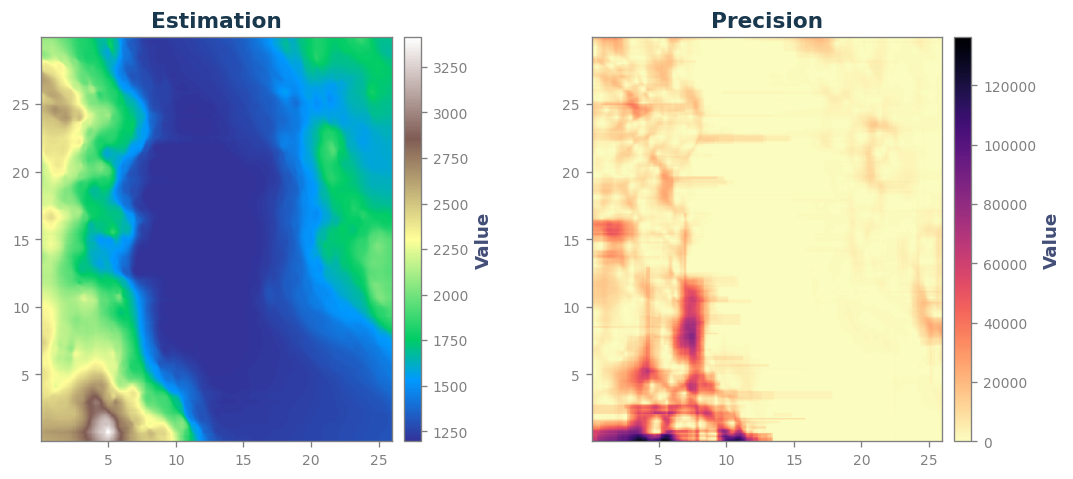

In [5]:
result.quick_plot(estimation_cmap="terrain", precision_cmap="magma_r")

The precision is the mean squared deviation of the members from the estimate. Where the partitions
disagree, the map depends on how the domain is cut. It is largest on the steep slopes, where neighbouring data
differ most, and along the southern edge below the highest peak, where the data stop. It is smallest
on the flat lake floor. The straight streaks come from the cuts of the partitions, which run parallel
to the axes.

true mean absolute error 35.1 m


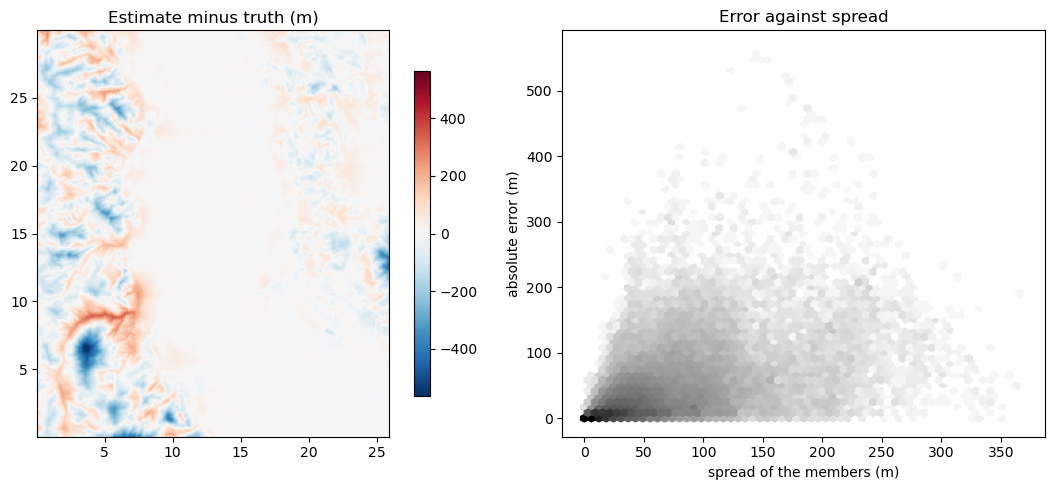

correlation of the spread with the absolute error 0.57


In [6]:
estimate = result.estimation()
error = estimate - truth
print(f"true mean absolute error {MAE(truth.ravel(), estimate.ravel()):.1f} m")

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
lim = np.abs(error).max()
im = axes[0].imshow(error.T, origin="lower", extent=extent, cmap="RdBu_r", vmin=-lim, vmax=lim)
axes[0].set_title("Estimate minus truth (m)")
fig.colorbar(im, ax=axes[0], shrink=0.8)
spread = np.sqrt(result.precision())
axes[1].hexbin(spread.ravel(), np.abs(error).ravel(), gridsize=60, bins="log", cmap="Greys")
axes[1].set_xlabel("spread of the members (m)"); axes[1].set_ylabel("absolute error (m)")
axes[1].set_title("Error against spread")
plt.tight_layout()
plt.show()
print(f"correlation of the spread with the absolute error {np.corrcoef(spread.ravel(), np.abs(error).ravel())[0, 1]:.2f}")

The errors follow the relief, small on the lake and large along the ridges and gullies of the
ranges, which 780 data cannot resolve. The spread of the members rises where the errors do, so the precision
map points at the places to distrust, although at a single location the error can be much larger or
smaller than the spread.

### The members

The estimate is a summary of the members, which `esi_samples()` returns, one per partition at every
location. At a location on the slope of the Wassuk Range they form the law of the elevation there.

members of shape (260, 300, 200)


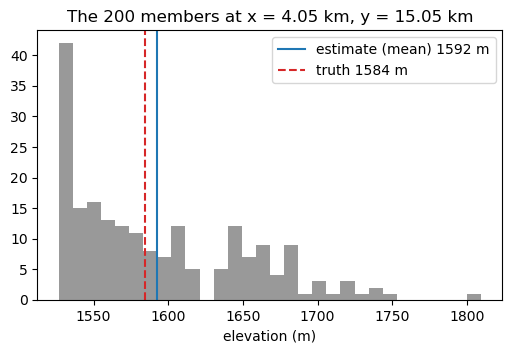

In [7]:
members = result.esi_samples()
print(f"members of shape {members.shape}")
i, j = np.searchsorted(xs, 4.0), np.searchsorted(ys, 15.0)
at = members[i, j]
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(at, bins=30, color="0.6")
ax.axvline(estimate[i, j], color="C0", label=f"estimate (mean) {estimate[i, j]:.0f} m")
ax.axvline(truth[i, j], color="C3", ls="--", label=f"truth {truth[i, j]:.0f} m")
ax.set_xlabel("elevation (m)"); ax.set_title(f"The 200 members at x = {xs[i]:.2f} km, y = {ys[j]:.2f} km")
ax.legend()
plt.show()

Each member is one partition's prediction. Their mean gives the map, their spread the
precision. Other summaries of the same members, the median or a quantile, give other maps without
recomputing anything (`result.re_estimate`), as the tutorials on uncertainty show.

### Scattered queries

`esi_nongriddata` takes any set of locations as an array of shape `(n, 2)`. Here the locations follow
a transect across the domain, from the Wassuk Range over the lake to the eastern hills, where the
members give a band around the estimate.

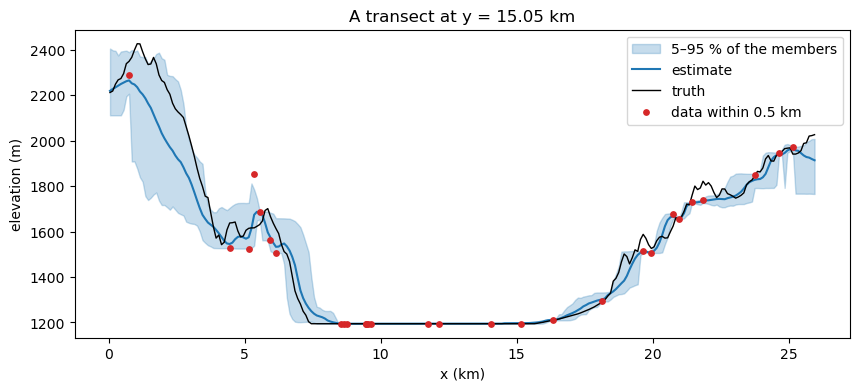

the truth lies within the band on 77% of the transect


In [8]:
row = np.searchsorted(ys, 15.0)
transect = np.column_stack([xs, np.full(len(xs), ys[row])])
along = esi_nongriddata(points, values, transect, n_partitions=200, best_params_found=best, seed=0)
low, high = np.nanpercentile(along.esi_samples(), [5, 95], axis=1)

fig, ax = plt.subplots(figsize=(10, 4))
ax.fill_between(xs, low, high, color="C0", alpha=0.25, label="5–95 % of the members")
ax.plot(xs, along.estimation(), color="C0", label="estimate")
ax.plot(xs, truth[:, row], color="k", lw=1, label="truth")
near = np.abs(points[:, 1] - ys[row]) < 0.5
ax.scatter(points[near, 0], values[near], color="C3", s=15, zorder=3, label="data within 0.5 km")
ax.set_xlabel("x (km)"); ax.set_ylabel("elevation (m)"); ax.set_title(f"A transect at y = {ys[row]:.2f} km")
ax.legend()
plt.show()
inside = np.mean((truth[:, row] >= low) & (truth[:, row] <= high))
print(f"the truth lies within the band on {inside:.0%} of the transect")

The band is narrow on the lake and wide on the slopes, as the precision map showed. The truth stays
inside it along most of the transect. Where it leaves the band, the members are too close to each
other, since an averaging decoder keeps the variation between cells but not the variation within
them. Reading the members as a calibrated law is the subject of the tutorials on uncertainty.

## What can go wrong

- **The shape of the queries.** `esi_griddata` wants `(2, nx, ny)` (a stack of coordinate grids),
  `esi_nongriddata` wants `(n, 2)` (one row per location). A transposed array gives a map of the
  wrong shape or an error.
- **Far from the data.** Every member is a prediction from data in a cell, so far outside the data
  the map repeats the nearest data. Keep the queries within the region the data cover.
- **The precision is not the error.** It measures how much the partitions disagree, which tracks the
  error over a region but not at every location.
- **An isotropic decoder on a field that is not.** Plain IDW on these ranges draws bull's-eyes around
  the data, as the first exercise below shows.

## Try it yourself

1. Replace `best_params_found=best` by `local_interpolator="idw", exponent=2.0, alpha=best["alpha"]`
   and compare the map and its true error.
2. Draw fewer data with `load_elevation_walker_lake(n_samples=200)` and watch the precision grow.
3. Summarise the members with the median, `result.re_estimate(spatialize.gs.esi.aggfunction.median)`.
4. Run the same steps on `load_reflectance_sundarbans()`, a field of sharp channels.

## Next

- *The session*, for the settings used here and the others (threads, display, the domain).
- *Choosing an ensemble with the Pareto search*, for how the parameters were chosen.
- *Uncertainty at a location*, to read the members as a law.
- *The decoders*, for the adaptive IDW and the other local interpolators.
- The documentation's [API reference](https://spatialize.readthedocs.io/en/latest/reference/index.html).